In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import ast
import scipy
import mdtraj as md
from typing import Dict, Tuple
import os
from sklearn.linear_model import LinearRegression
import sys
import pyblock
bme_dir = '/projects/lindorff_group/people/thd711/HDX_project/code/BME/' # replace this with your local copy of the BME code
sys.path.append(bme_dir)
import BME as BME

# matplotlib settings
# --- Publication style settings ---
plt.rcParams.update({
    # Font
    "font.family": "Times New Roman",
    "font.serif": ["Arial"],  # or other preferred serif font
    "mathtext.fontset": "cm",            # Computer Modern for math text
    "text.usetex": False,                 # Use LaTeX for text rendering]
    "pdf.fonttype": 42,                 # Use LaTeX for text rendering

    # Figure
    "figure.figsize": (6, 4),            # width, height in inches
    "figure.dpi": 150,                   # medium resolution

    # Axes
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "axes.linewidth": 1.2,
    "axes.grid": True,                   # optional, remove if you want no grid
    "grid.linestyle": "--",
    "grid.alpha": 0.7,

    # Ticks
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,

    # Lines
    "lines.linewidth": 2,
    "lines.markersize": 6,

    # Legend
    "legend.fontsize": 10,
    "legend.frameon": False
})

def find_xtc_filenames(path_to_dir, suffix=".xtc"):
    filenames = os.listdir(path_to_dir)
    return [filename for filename in filenames if filename.endswith(suffix)]

# --- Utility functions ---
def RMSE(actual, predicted):
    actual = np.array(actual)
    predicted = np.array(predicted)
    return np.sqrt(np.mean((actual - predicted)**2))

# Function to calculate helical fraction
def helical_fraction(ss_line):
    helix_chars = {'H', 'G', 'I'}
    n_residues = len(ss_line)
    n_helical = sum(1 for c in ss_line if c in helix_chars)
    return n_helical / n_residues

# Function to calculate per-residue helicity per frame
def dssp_to_helicity(dssp_lines):
    """
    Convert DSSP strings into a binary helicity matrix.
    
    Parameters
    ----------
    dssp_lines : list of str
        Each entry corresponds to one frame.
        Each string is the DSSP assignment per residue for that frame.
    
    Returns
    -------
    helicity : np.ndarray
        Array of shape (n_frames, n_residues).
        1 = helix ('H', 'G', 'I'), 0 = non-helix.
    """
    helix_codes = {'H', 'G', 'I'}
    
    n_frames = len(dssp_lines)
    n_residues = len(dssp_lines[0])
    
    helicity = np.zeros((n_frames, n_residues), dtype=int)
    
    for i, line in enumerate(dssp_lines):
        helicity[i, :] = [1 if c in helix_codes else 0 for c in line]
    
    return helicity

# functions for analysis of RDCs
# function to parse calculated RDC data
def read_calc_RDCs(filename):
    residues = []
    data = []
    with open(filename,'r') as f:
        lines = f.readlines()
        for line in lines[1:]:
            residues.append(int(line.split(',')[0]))

        for line in lines[1:]:
            dat = np.array(line.split(',')[1:]).astype(float)
            data.append(dat)

    data = np.array(data).T * -1 # account for negative gyromagnetic ratio of 15N

    return residues, data

def scale_rdcs_to_minimize_q(calc, exp, weights, prior='True', scale_matching = 'True'):
    calc = np.array(calc)
    exp = np.array(exp)

    if prior=='True':
        mask_nan = ~np.isnan(weights) # to remove unphysical conformations from averagin
        calc = np.average(calc[mask_nan, :], axis=0)
    else:
        weights = np.nan_to_num(weights,nan=0)
        weights = weights / np.sum(weights)
        calc = np.average(calc, weights=weights, axis=0)

    # if scale_matching - extract datapoints satisfying this
    if scale_matching=='True':
        try:
            prod = calc*exp
            keepidxs = np.where(prod>0)[0]
            #print('keeping {} / {} datapoints for scaling...'.format(keepidxs.shape[0], calc.shape[0]))
            calcfilt = calc[keepidxs]
            expfilt = exp[keepidxs]
            # Compute unconstrained scaling factor
            s = np.sum(calcfilt * expfilt) / np.sum(calcfilt ** 2)
        except:
            print('Warning: no matching RDCs found for scaling, returning nothing...')
            return

    else:
        # Compute unconstrained scaling factor
        s = np.sum(calc * exp) / np.sum(calc ** 2)

    # Constrain s to be ≥ 0 (should be satisfied already if scale_matching)
    s = max(s, 0)

    scaled = s * calc
    q = np.sqrt(np.mean((scaled - exp)**2)) / np.sqrt(np.mean(exp**2))
    q_nonscaled = np.sqrt(np.mean((calc - exp)**2)) / np.sqrt(np.mean(exp**2))

    return scaled, s, q, q_nonscaled

outpath='./'
hyres_path = '../../MD_DATA/'
amber_path = '../../AMBER_IDPs/'
hyres_gpu_path = '../../HYRES_GPU_IDPs/'
exp_data_path = '../../ORTHOGONAL_EXP_DATA/'
ensembles = ['a99SB*-ILDN TIP3P', 'HyRes-GPU', 'HyRes-Opt']
ensemble_paths = [amber_path, hyres_gpu_path, hyres_path]


findfont: Font family ['Times New Roman'] not found. Falling back to DejaVu Sans.
findfont: Font family ['Times New Roman'] not found. Falling back to DejaVu Sans.
findfont: Font family ['Times New Roman'] not found. Falling back to DejaVu Sans.


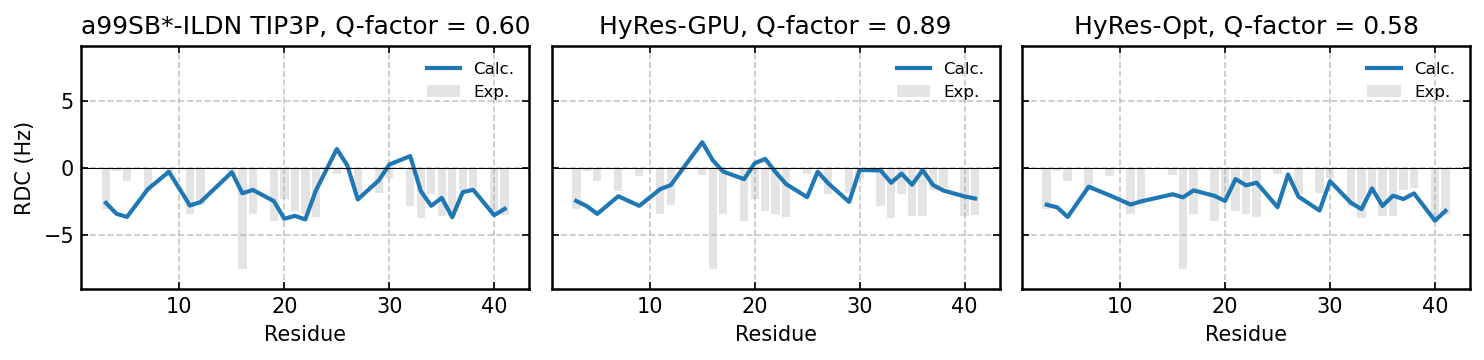

In [2]:
import MDAnalysis

# comparison with NMR RDCs
protein = 'Ab42'
ensembles = ['a99SB*-ILDN TIP3P', 'HyRes-GPU', 'HyRes-Opt']
ensemble_paths = [amber_path, hyres_gpu_path, hyres_path]

# experimental data
expres = np.loadtxt(exp_data_path+f'/{protein}/RDC_HN.dat').astype(int)[:,0]
exprdc = np.loadtxt(exp_data_path+f'/{protein}/RDC_HN.dat')[:,1]
# remove nan rows
exp_mask_nan = ~np.isnan(exprdc)
expres = expres[exp_mask_nan]
exprdc = exprdc[exp_mask_nan]

# number of total residues
prot_length=MDAnalysis.Universe(hyres_path+f'./{protein}/protein.pdb').select_atoms('name CA').indices.shape[0]
# remove first and last residue from experiment
if expres[0]==1:
    expres=expres[1:]
    exprdc=exprdc[1:]
elif expres[-1]==prot_length:
    expres=expres[:-1]
    exprdc=exprdc[:-1]

yscale = np.max(np.abs(exprdc))*1.2


# storage
all_calc_residues = []
all_scaled_RDCs = []
all_Qfactor_prior = []

for ensemble, path in zip(ensembles, ensemble_paths):

    traj_names = np.sort(find_xtc_filenames(path + f'./{protein}/'))

    # load RDC data
    for i in range(len(traj_names)):
        if i==0:
            residues, data = read_calc_RDCs(path+f'./{protein}/RDC/RDC_{traj_names[i]}.csv')
        else:
            residues, tmpdata = read_calc_RDCs(path+f'./{protein}/RDC/RDC_{traj_names[i]}.csv')
            data= np.concatenate((data, tmpdata), axis=0)

    # sim indices for which there are experiments
    idxs = []
    for ele in expres:
        idx = list(residues).index(ele)
        idxs.append(idx)
    idxs=np.array(idxs).astype(int)
    sim_rdc_residues= np.array(residues)[idxs]
    data = np.array(data)[:,idxs]
        
        
    # uniform prior weights
    prior_weights = np.ones(data.shape[0]) / data.shape[0]
    scaled, s, q, q_nonscaled = scale_rdcs_to_minimize_q(data, exprdc, prior_weights, prior='False', scale_matching='True')
    

    all_calc_residues.append(sim_rdc_residues)
    all_scaled_RDCs.append(scaled)
    all_Qfactor_prior.append(q)
    
# plot
fig, axes = plt.subplots(
    1, 3,
    figsize=(10., 2.5),
    sharex=True,
    sharey=True
)

for ax, ensemble, calc_residues, RDC_prior, qfactor in zip(
    axes,
    ensembles,
    all_calc_residues,
    all_scaled_RDCs,
    all_Qfactor_prior
):

    # experimental secondary shifts
    ax.bar(
        expres,
        exprdc,
        color='lightgrey',
        alpha=0.6,
        label='Exp.'
    )

    # ensemble-averaged secondary shifts
    ax.plot(
        calc_residues,
        RDC_prior,
        linewidth=2.0,
        linestyle='solid',
        color = 'tab:blue',
        label = 'Calc.'
    )

    ax.axhline(0, color='k', linewidth=0.5)

    ax.set_title(
        f'{ensemble}, Q-factor = {qfactor:.2f}'
    )
    ax.set_xlabel('Residue')
    ax.set_ylim(-yscale, yscale)
    ax.legend(frameon=False, fontsize=8)

axes[0].set_ylabel(f'RDC (Hz)')

plt.tight_layout()
plt.savefig('plots_RDCs.png')
plt.show()